In [20]:
from rdkit import Chem


In [21]:
from rdkit import Chem
from rdkit.Chem import AllChem, Draw
from PIL import Image, ImageDraw
import numpy as np
import json
import pickle
from pathlib import Path

def ensure_2d(mol):
    if mol.GetNumConformers() == 0:
        AllChem.Compute2DCoords(mol)
    return mol.GetConformer()

def atom_pixel_positions(mol, size=(400, 300), pad_frac=0.12):
    """
    Map atom 2D coordinates to pixel coordinates for an image of given size.
    Returns list of (x_px, y_px) for each atom.
    """
    w, h = size
    conf = ensure_2d(mol)
    coords = np.array([[conf.GetAtomPosition(i).x, conf.GetAtomPosition(i).y] for i in range(mol.GetNumAtoms())])
    minxy = coords.min(axis=0)
    maxxy = coords.max(axis=0)
    # prevent zero-size
    span = np.maximum(maxxy - minxy, 1e-6)
    pad_px = pad_frac * min(w, h)
    scale = min((w - 2 * pad_px) / span[0], (h - 2 * pad_px) / span[1])
    # map x -> [pad_px, w-pad_px], y -> [pad_px, h-pad_px] but flip y for image coords
    x_px = (coords[:, 0] - minxy[0]) * scale + pad_px
    y_px = (coords[:, 1] - minxy[1]) * scale + pad_px
    y_px = h - y_px  # flip to image coordinate system
    return [(float(x), float(y)) for x, y in zip(x_px, y_px)]

def _cubic_bezier_points(p0, p1, p2, p3, n=64):
    t = np.linspace(0, 1, n)[:, None]
    omt = 1 - t
    pts = (omt**3) * p0 + 3 * (omt**2) * t * p1 + 3 * omt * (t**2) * p2 + (t**3) * p3
    return [tuple(pt) for pt in pts]

def _rotate(vec, angle_rad):
    c, s = np.cos(angle_rad), np.sin(angle_rad)
    return np.array([vec[0] * c - vec[1] * s, vec[0] * s + vec[1] * c])

def _draw_open_arrowhead(draw, tip, direction, size=12, color=(255,0,0), width=3, angle_deg=28):
    """
    Draw a V-shaped arrowhead (common in curved mechanism arrows).
    `direction` should be a unit vector pointing toward the tip.
    """
    angle = np.deg2rad(angle_deg)
    left_dir = _rotate(direction, angle)
    right_dir = _rotate(direction, -angle)
    left = np.array(tip) - left_dir * size
    right = np.array(tip) - right_dir * size
    draw.line([tuple(tip), tuple(left)], fill=color, width=width)
    draw.line([tuple(tip), tuple(right)], fill=color, width=width)

def _draw_filled_arrowhead(draw, tip, direction, size=12, color=(255,0,0)):
    perp = np.array([-direction[1], direction[0]])
    base_center = np.array(tip) - np.array(direction) * size
    left = base_center + perp * (size * 0.45)
    right = base_center - perp * (size * 0.45)
    draw.polygon([tuple(tip), tuple(left), tuple(right)], fill=color)

def draw_curly_arrow_on_image(img, start_px, end_px, curvature=0.25, curl=0.18, color=(255,0,0), width=4,
                              head_style='open', head_size=None, head_angle=28):
    """
    Draw a curly (curved) arrow using a cubic Bezier with a subtle tail curl.
    curvature: overall bow of the curve (positive -> left of direction).
    curl: small tail curl for a more 'mechanism' style look.
    head_style: 'open' or 'filled'.
    """
    draw = ImageDraw.Draw(img)
    p0 = np.array(start_px, dtype=float)
    p3 = np.array(end_px, dtype=float)
    vec = p3 - p0
    dist = np.linalg.norm(vec)
    if dist < 1e-6:
        return
    unit = vec / dist
    perp = np.array([-unit[1], unit[0]])

    # cubic control points with a consistent bow
    c1 = p0 + vec * 0.25 + perp * (dist * curvature)
    c2 = p0 + vec * 0.75 + perp * (dist * curvature)
    pts = _cubic_bezier_points(p0, c1, c2, p3, n=72)

    # subtle tail curl to mimic hand-drawn curly arrows
    if curl and abs(curl) > 1e-6:
        t = np.linspace(0, 1, len(pts))
        amp = dist * curl * 0.12
        # emphasize near the tail, fade toward the head
        offset = (np.sin(2 * np.pi * t) * (1 - t))[:, None] * perp * amp
        pts = [tuple(np.array(p) + off) for p, off in zip(pts, offset)]

    draw.line(pts, fill=color, width=width)

    # arrowhead direction from the last segment
    tail = np.array(pts[-2])
    tip = np.array(pts[-1])
    dir_vec = tip - tail
    dir_norm = np.linalg.norm(dir_vec)
    if dir_norm < 1e-6:
        return
    direction = dir_vec / dir_norm

    if head_size is None:
        head_size = max(6, int(dist * 0.08))
    if head_style == 'filled':
        _draw_filled_arrowhead(draw, tuple(tip), direction, size=head_size, color=color)
    else:
        _draw_open_arrowhead(draw, tuple(tip), direction, size=head_size, color=color, width=max(2, width - 1), angle_deg=head_angle)

def render_arrows_hi_res(mol, arrows, size=(450, 350), scale=2):
    """Render at higher resolution and downsample for smoother arrows.
    """
    if scale <= 1:
        return draw_mol_with_arrows(mol, arrows=arrows, size=size)
    big_size = (int(size[0] * scale), int(size[1] * scale))
    img = draw_mol_with_arrows(mol, arrows=arrows, size=big_size, arrow_width=4 * scale)
    return img.resize(size, resample=Image.Resampling.LANCZOS)

def draw_mol_with_arrows(mol, arrows, size=(400,300), curvature=0.25, curl=0.18, arrow_color=(255,0,0),
                         arrow_width=4, bg_color=(255,255,255), head_style='open'):
    """
    Draw molecule using RDKit and overlay curly arrows.
    - mol: RDKit Mol
    - arrows: list of (start_atom_idx, end_atom_idx), (bond_idx, end_atom_idx),
      or dicts with keys ('start','end','curvature','curl','color','width','head_style')
      where 'start'/'end' can be an atom index or ('bond', bond_idx) tuple
    Returns a PIL.Image.
    """
    ensure_2d(mol)
    pil_img = Draw.MolToImage(mol, size=size, kekulize=True, wedgeBonds=True, bg=bg_color)
    atom_pos = atom_pixel_positions(mol, size=size)

    def get_position(spec):
        if isinstance(spec, int):
            return atom_pos[spec]
        if isinstance(spec, tuple) and spec[0] == 'bond':
            bond_idx = spec[1]
            bond = mol.GetBondWithIdx(bond_idx)
            begin_pos = np.array(atom_pos[bond.GetBeginAtomIdx()])
            end_pos = np.array(atom_pos[bond.GetEndAtomIdx()])
            return tuple((begin_pos + end_pos) / 2.0)
        return atom_pos[spec]

    # normalize arrows input
    normal_arrows = []
    for a in arrows:
        if isinstance(a, (list, tuple)) and len(a) >= 2:
            s, e = a[0], a[1]
            kw = {}
            if len(a) > 2 and isinstance(a[2], dict):
                kw = a[2]
            normal_arrows.append({
                'start': s, 'end': e,
                'curvature': kw.get('curvature', curvature),
                'curl': kw.get('curl', curl),
                'color': kw.get('color', arrow_color),
                'width': kw.get('width', arrow_width),
                'head_style': kw.get('head_style', head_style),
                'head_size': kw.get('head_size', None),
                'head_angle': kw.get('head_angle', 28),
            })
        elif isinstance(a, dict):
            normal_arrows.append({
                'start': a['start'], 'end': a['end'],
                'curvature': a.get('curvature', curvature),
                'curl': a.get('curl', curl),
                'color': a.get('color', arrow_color),
                'width': a.get('width', arrow_width),
                'head_style': a.get('head_style', head_style),
                'head_size': a.get('head_size', None),
                'head_angle': a.get('head_angle', 28),
            })

    for a in normal_arrows:
        start_px = get_position(a['start'])
        end_px = get_position(a['end'])
        draw_curly_arrow_on_image(
            pil_img, start_px, end_px,
            curvature=a['curvature'],
            curl=a['curl'],
            color=a['color'],
            width=a['width'],
            head_style=a['head_style'],
            head_size=a['head_size'],
            head_angle=a['head_angle'],
        )
    return pil_img

# ---- Mechanism helpers (from molecule-web-app/backend/rules/rules.py) ----
# Mechanism tuple: [code, i, j, k, l]
# code meanings (inferred from rules.py):
# 0: atom -> atom (bond formation)
# 1: atom -> bond (attack on bond)
# 2: bond -> atom (bond donation to atom)
# 3: bond -> bond (bond donation to bond)
# 4: atom -> atom (proton transfer)
# 5: bond -> atom (proton transfer)
# 6: atom -> atom (hydride transfer)
# 7: atom -> bond (hydride to bond)
# 8: elimination (base -> CH, bond -> bond)
# 9: elimination (base -> CH, atom -> atom)
# 10: bond -> atom (carbocation formation)

def bond_idx(mol, a, b):
    bond = mol.GetBondBetweenAtoms(int(a), int(b))
    return None if bond is None else bond.GetIdx()

def _bond_spec(mol, a, b):
    idx = bond_idx(mol, a, b)
    if idx is None:
        return None
    return ('bond', idx)

def get_or_get_or_add_explicit_h(mol, atom_idx):
    """
    Ensure an explicit H is bonded to atom_idx and return (mol, h_idx).
    If an H neighbor already exists, reuse it.
    """
    m = Chem.RWMol(mol)
    a = m.GetAtomWithIdx(int(atom_idx))
    for n in a.GetNeighbors():
        if n.GetAtomicNum() == 1:
            return m.GetMol(), n.GetIdx()
    # prevent implicit H masking the explicit one
    a.SetNoImplicit(True)
    a.SetNumExplicitHs(0)
    h = Chem.Atom(1)
    h_idx = m.AddAtom(h)
    m.AddBond(int(atom_idx), h_idx, Chem.BondType.SINGLE)
    new_mol = m.GetMol()
    Chem.SanitizeMol(new_mol)
    return new_mol, h_idx

def mechanism_to_arrows(mol, mechanism, base_style=None, add_proton_explicit=False, add_bond_break=True):
    """
    Convert a single mechanism [code, i, j, k, l] into arrow specs.
    If add_proton_explicit is True, proton transfers draw to an explicit H.
    Returns (arrows, mol_for_render).
    """
    if base_style is None:
        base_style = {}
    code, i, j, k, l = mechanism
    arrows = []
    mol_for_render = mol

    def add_arrow(start, end, extra=None):
        spec = {'start': start, 'end': end}
        spec.update(base_style)
        if extra:
            spec.update(extra)
        arrows.append(spec)

    if code in (0, 4, 6):
        # atom -> atom (bond formation / proton transfer / hydride transfer)
        if code == 4 and add_proton_explicit:
            mol_for_render, h_idx = get_or_add_explicit_h(mol, j)
            add_arrow(i, h_idx)
        else:
            add_arrow(i, j)
    elif code in (1, 7):
        # atom -> bond (attack on bond)
        end_spec = _bond_spec(mol, j, l)
        if end_spec is not None:
            # draw to attacked atom (j), not the bond midpoint
            add_arrow(i, j)
            if add_bond_break:
                # show bond breaking to the atom not attacked (leaving group)
                add_arrow(end_spec, l)
    elif code in (2, 5):
        # bond -> atom (bond donation to atom / proton transfer)
        start_spec = _bond_spec(mol, i, k)
        if start_spec is not None:
            if code == 5 and add_proton_explicit:
                mol_for_render, h_idx = get_or_add_explicit_h(mol, j)
                add_arrow(start_spec, h_idx)
            else:
                add_arrow(start_spec, j)
    elif code == 3:
        # bond -> bond
        start_spec = _bond_spec(mol, i, k)
        end_spec = _bond_spec(mol, j, l)
        if start_spec is not None and end_spec is not None:
            add_arrow(start_spec, end_spec)
            if add_bond_break:
                add_arrow(end_spec, l)
    elif code == 8:
        # elimination: base -> CH and bond -> bond
        add_arrow(i, j)
        start_spec = _bond_spec(mol, k, l)
        end_spec = _bond_spec(mol, j, k)
        if start_spec is not None and end_spec is not None:
            add_arrow(start_spec, end_spec)
            if add_bond_break:
                add_arrow(end_spec, k)
    elif code == 9:
        # elimination: base -> CH and atom -> atom
        add_arrow(i, j)
        add_arrow(j, k)
    elif code == 10:
        # bond -> atom (carbocation formation)
        start_spec = _bond_spec(mol, j, l)
        if start_spec is not None:
            add_arrow(start_spec, j)

    return arrows, mol_for_render

def mechanism_set_to_arrows(mol, mechanisms, base_style=None):
    arrows = []
    for mech in mechanisms:
        mech_arrows, _ = mechanism_to_arrows(mol, mech, base_style=base_style, add_proton_explicit=False, add_bond_break=True)
        arrows.extend(mech_arrows)
    return arrows

def load_training_mechanisms(data_json_path):
    data = json.loads(Path(data_json_path).read_text())
    choices = data.get('choices', {})
    return [choices[k]['mechanism'] for k in sorted(choices, key=lambda x: int(x))]

def load_training_mol(pkl_path):
    return pickle.loads(Path(pkl_path).read_bytes())

def load_training_sm(pkl_path):
    """Load starting molecule (sm.pkl)"""
    return pickle.loads(Path(pkl_path).read_bytes())

def load_training_case(case_id, base_dir='training_sets/20260202'):
    """Return (mol, mechanisms) for a case number within base_dir.
    Uses sm.pkl for the starting molecule.
    """
    case_dir = Path(base_dir) / str(case_id)
    mol = load_training_sm(case_dir / 'sm.pkl')
    mechanisms = load_training_mechanisms(case_dir / 'data.json')
    return mol, mechanisms



mechanism 0: [0, 9, 3, None, None]


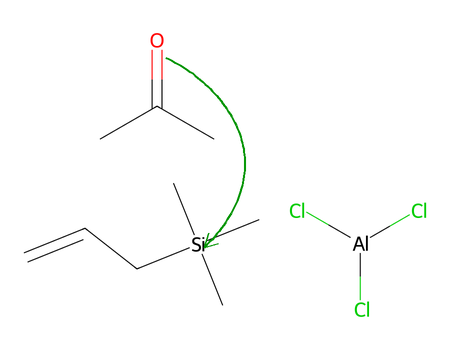

mechanism 1: [8, 9, 7, 8, 9]


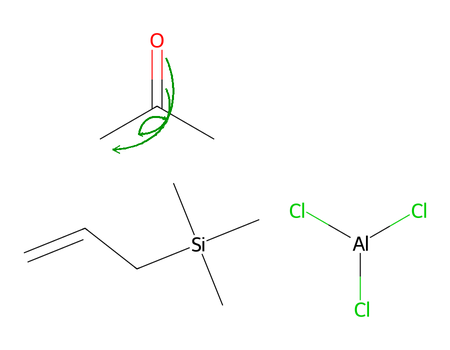

mechanism 2: [0, 9, 12, None, None]


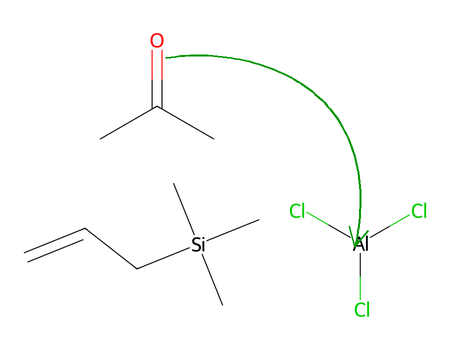

mechanism 3: [0, 11, 3, None, None]


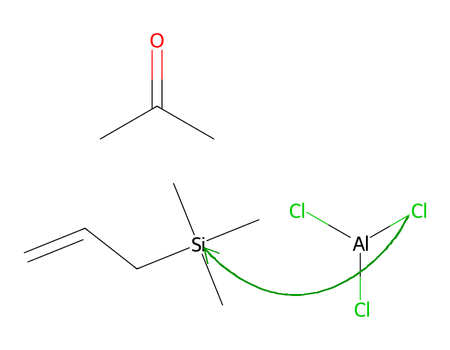

mechanism 4: [8, 11, 7, 8, 9]


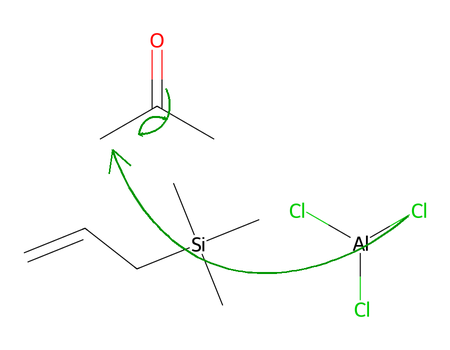

mechanism 5: [0, 11, 12, None, None]


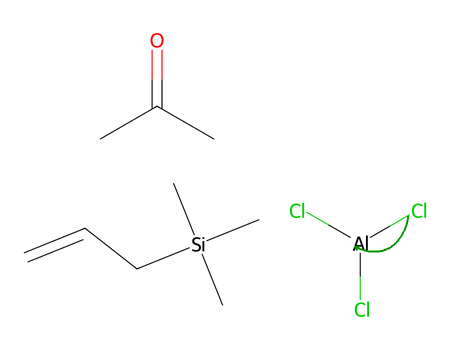

mechanism 6: [1, 9, 0, None, 1]


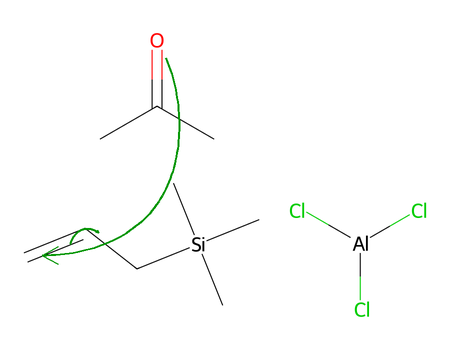

mechanism 7: [1, 9, 1, None, 0]


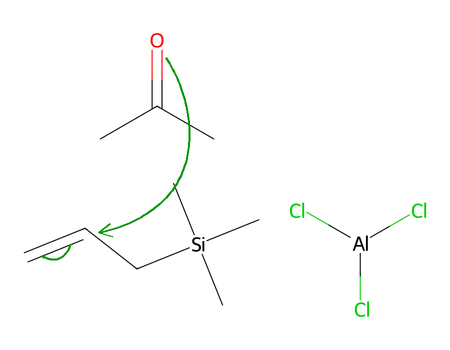

mechanism 8: [1, 11, 0, None, 1]


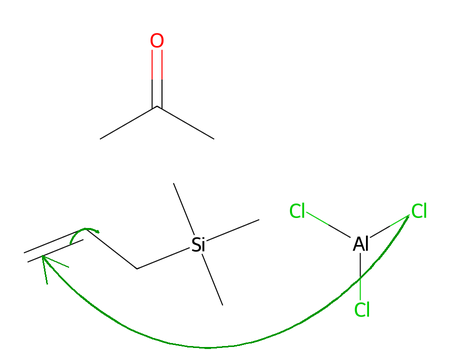

mechanism 9: [1, 11, 1, None, 0]


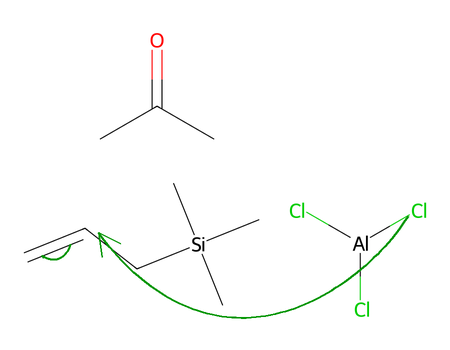

mechanism 10: [1, 11, 8, None, 9]


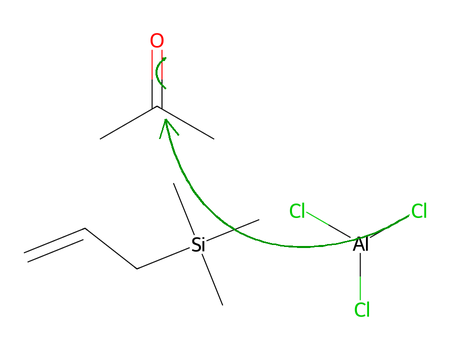

TypeError: int() argument must be a string, a bytes-like object or a real number, not 'NoneType'

In [22]:
# Example: draw one image per mechanism from training data
case_id = 6
mol, mechanisms = load_training_case(case_id)

for idx, mech in enumerate(mechanisms):
    arrows, mol_render = mechanism_to_arrows(
        mol,
        mech,
        base_style={'color': (0, 150, 0), 'width': 4, 'curvature': -0.4},
        add_proton_explicit=True,
        add_bond_break=True,
    )
    print(f'mechanism {idx}: {mech}')
    img = render_arrows_hi_res(mol_render, arrows=arrows, size=(450, 350), scale=2)
    display(img)
